# Diffusivity along trajectories

Quantitative companion to §3 of `well_walrus_dataset_categorisation.md`. For one scalar field per dataset, each frame $f$ gives three numbers:

| Metric | Definition | Reading |
|---|---|---|
| (a) variance ratio | $\sigma^2(t)/\sigma^2(0)$, with $\sigma^2$ the spatial variance (the VRMSE denominator) | 1 at start; $\to 0$: homogenising; flat: structure kept; rising: instability or driving |
| (b) relative spread | $\sigma(t)/\sigma_{\rm global}$, with $\sigma_{\rm global}$ the field's `std` in the dataset's `stats.yaml` (Walrus's normalisation statistic) | absolute level; shows whether the end state is near-uniform for that dataset |
| (c) length scale | $\ell(t) = \sigma / \sqrt{\langle\lvert\nabla f\rvert^2\rangle}$, in grid cells ($\nabla$ by forward differences) | typical feature size; diffusion makes it grow (coarsening), shocks and filaments keep it small |

We take 8 trajectories per dataset, from files spread evenly over its parameter range; 50 frames each over the whole trajectory; time as $t/T$. 3D datasets use the full volume. PNS and RSG are not on disk.

## Parameter sweeps

Many datasets have some physical settings which can change the behavious. We can sweep over one setting while keeping the others fixed. Each value is one file on disk; each curve in §3 is one value, the median of 5 trajectories (different initial conditions, but same settings). In total: 8 sweeps, 46 values, 230 trajectories, 50 frames each. This is separate from the 8 trajectories per dataset in §1–2.

| Sweep | Constant | Interpretation | Values | Affects Dissusion? |
|---|---|---|---|---|
| `shear_flow` $Re$ ($Sc = 1$) | Reynolds number $Re$ | Inertia vs viscosity; high $Re$ is a runny fluid that keeps fine eddies. $\nu = 1/Re$ | 4 ($10^4$ to $5\times10^5$) | **Yes**: higher $Re$, less diffusion |
| `shear_flow` $Sc$ ($Re = 10^5$) | Schmidt number $Sc$ | How slowly the tracer spreads compared with momentum. $D = 1/(Re\,Sc)$ | 7 ($0.1$ to $10$) | **Yes**: higher $Sc$, less tracer diffusion |
| `rayleigh_benard` $Ra$ ($Pr = 1$) | Rayleigh number $Ra$ | Strength of heating from below vs heat and momentum diffusion. $\kappa, \nu \propto Ra^{-1/2}$ | 5 ($10^6$ to $10^{10}$) | **Yes**: higher $Ra$, less diffusion |
| `turbulent_radiative_layer_2D` | Cooling time $t_{\rm cool}$ | How fast the gas radiates heat away; short is strong cooling | 9 ($0.03$ to $3.16$) | No: an energy sink, not diffusion |
| `viscoelastic_instability` | Flow regime (AH, CAR, EIT) | Same polymer fluid in three states: steady arrowhead, chaotic arrowhead, elasto-inertial turbulence | 3 | No: same coefficients in all three |
| `euler_multi_quadrants` (periodic) | Adiabatic index $\gamma$ | Gas stiffness: how much pressure rises on compression; set by gas type (propane to argon) | 10 ($1.13$ to $1.76$) | No: inviscid at every value |
| `MHD` ($M_A = 2$) | Sonic Mach number $M_s$ | Turbulent speed vs sound speed; above 1 is supersonic, with shocks | 5 ($0.5$ to $7$) | No: ideal MHD |
| `turbulence_gravity_cooling` ($\rho_0 = 4.45$, $T_0 = 100$) | Metallicity $Z$ | Heavy-element content, which sets cooling strength; $Z = 0$ is no cooling | 3 ($0$, $0.1$, $1$) | No: cooling strength |

The first three change the amount of diffusion: if the metrics measure diffusion, their curves should order by $Re$, $Sc$ or $Ra$, with the lowest homogenising fastest. The other five change no diffusion term, so differences between their curves come from the regime (shocks, cooling, chaos). They check that the metrics are not just tracking how dynamic the flow is.

In [10]:
import json, re
from pathlib import Path
import h5py, numpy as np, yaml, matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.animation import FuncAnimation, PillowWriter

ROOT = Path("/leonardo_work/ICT26_MHPC_0/sshamsi/datasets")
CACHE = Path("diffusivity_metrics.json")
N, K, KS = 50, 8, 5  # frames per trajectory, trajectories per dataset, trajectories per sweep value
T = np.linspace(0, 1, N)  # common t/T grid for medians

FIELD = {  # dataset -> (field, component); one scalar per dataset
    "shear_flow": ("t0_fields/tracer", ()),
    "rayleigh_benard": ("t0_fields/buoyancy", ()),
    "viscoelastic_instability": ("t2_fields/C", (0, 0)),   # C_xx
    "gray_scott_reaction_diffusion": ("t0_fields/A", ()),
    "active_matter": ("t0_fields/concentration", ()),
    "rayleigh_taylor_instability": ("t0_fields/density", ()),
    "planetswe": ("t0_fields/height", ()),
    "acoustic_scattering_discontinuous": ("t0_fields/pressure", ()),
    "acoustic_scattering_inclusions": ("t0_fields/pressure", ()),
    "acoustic_scattering_maze": ("t0_fields/pressure", ()),
    "helmholtz_staircase": ("t0_fields/pressure_re", ()),
    "euler_multi_quadrants_periodicBC": ("t0_fields/density", ()),
    "euler_multi_quadrants_openBC": ("t0_fields/density", ()),
    "turbulent_radiative_layer_2D": ("t0_fields/density", ()),
    "turbulent_radiative_layer_3D": ("t0_fields/density", ()),
    "MHD_64": ("t0_fields/density", ()),
    "supernova_explosion_128": ("t0_fields/density", ()),
    "turbulence_gravity_cooling": ("t0_fields/density", ()),
}
DIFFUSIVE = list(FIELD)[:7]
NON_DIFFUSIVE = list(FIELD)[7:]
SWEEPS = {  # name -> (dataset, file globs covering every value on disk, regex for the swept value or None)
    "shear_flow Re (Sc=1)": ("shear_flow", ["*Schmidt_1e0.*"], r"Reynolds_([^_]+)"),
    "shear_flow Sc (Re=1e5)": ("shear_flow", ["*Reynolds_1e5_*"], r"Schmidt_([^_]+)$"),
    "rayleigh_benard Ra (Pr=1)": ("rayleigh_benard", ["*Prandtl_1.*"], r"Rayleigh_([^_]+)"),
    "TRL2D t_cool": ("turbulent_radiative_layer_2D", ["*.hdf5"], r"tcool_([^_]+)$"),
    "viscoelastic regime": ("viscoelastic_instability", ["*_AH.*", "*_CAR.*", "*_EIT.*"], None),
    "EMQ periodic gamma": ("euler_multi_quadrants_periodicBC", ["*.hdf5"], r"gamma_([^_]+)"),
    "MHD Ms (Ma=2)": ("MHD_64", ["*Ma_2_*"], r"Ms_([^_]+)$"),
    "TGC Z (rho0=4.45, T0=100)": ("turbulence_gravity_cooling", ["*rho0_4.45_*T0_100.*"], r"_Z_([^_]+)_"),
}


def metrics(f, ds, traj):
    """Metrics (a)-(c) for N strided frames of one trajectory; one frame in memory at a time (3D volumes)."""
    field, comp = FIELD[ds]
    std = np.asarray(yaml.safe_load(open(ROOT / ds / "stats.yaml"))["std"][field.split("/")[1]])[comp]
    with h5py.File(f) as h:
        d = h[field]
        idx = np.unique(np.linspace(0, d.shape[1] - 1, N).astype(int))
        s, g = np.empty(len(idx)), np.empty(len(idx))
        for j, i in enumerate(idx):
            a = d[traj, i][(...,) + comp]  # float32; forward differences: np.gradient's float64 temporaries cost ~200x more on the login node
            s[j] = a.std(dtype=np.float64)
            g[j] = np.sqrt(sum(np.square(np.diff(a, axis=k)).mean(dtype=np.float64) for k in range(a.ndim)))
    with np.errstate(divide="ignore", invalid="ignore"):  # a uniform frame gives inf/nan; plots skip them
        return {"t": (idx / idx[-1]).tolist(), "a": (s ** 2 / s[0] ** 2).tolist(), "b": (s / std).tolist(), "c": (s / g).tolist()}


def files(ds, globs):
    return sorted({f for g in globs for f in (ROOT / ds / "data/train").glob(g)})


def subset(ds):
    """K (file, traj) pairs: files evenly spaced over the sorted list; with fewer than K files, extra trajectories."""
    fs = files(ds, ["*.hdf5"])
    sel = [fs[i] for i in np.linspace(0, len(fs) - 1, min(K, len(fs))).astype(int)]
    return [(sel[i % len(sel)], i // len(sel)) for i in range(K)]


def stack(ms, m):
    """Trajectories of metric m interpolated onto T -> (n_traj, N)."""
    return np.array([np.interp(T, x["t"], x[m]) for x in ms])


def value(name, stem):
    """(sort key, legend label) for one sweep file."""
    rx = SWEEPS[name][2]
    m = re.search(rx, stem) if rx else None
    return (float(m.group(1)), m.group(0).strip("_")) if m else (0, stem.rsplit("_", 1)[-1])


OUT = Path("gifs"); OUT.mkdir(exist_ok=True)
NG = 30                                                   # frames per GIF
LOG = {"supernova_explosion_128", "turbulence_gravity_cooling"}  # shown as log10 density (huge dynamic range)


def frames(f, ds, traj=0):
    """NG strided frames of the dataset's field (3D: z mid-plane) -> (T, rows, cols), x horizontal."""
    field, comp = FIELD[ds]
    with h5py.File(f) as h:
        d, dims = h[field], list(h["dimensions"].attrs["spatial_dims"])
        idx = np.unique(np.linspace(0, d.shape[1] - 1, NG).astype(int))
        a = d[(traj, idx, slice(None), slice(None)) + ((d.shape[4] // 2,) if len(dims) == 3 else ())][(...,) + comp]
    a = np.log10(a) if ds in LOG else a
    return a.swapaxes(1, 2) if dims[0] == "x" else a


def gif(name, panels):
    """Write gifs/{name}.gif from (title, frames) panels. Panels sized to their aspect; wide fields stack vertically."""
    titles, arrs = zip(*panels)
    r = [a.shape[2] / a.shape[1] for a in arrs]
    col = np.mean(r) > 1.5
    H = 9 / np.mean(r) if col else (4 if np.mean(r) >= 0.67 else 6)  # panel height, inches
    grid, size, key = ((len(arrs), 1), (9, H * len(arrs) + 0.6), "height_ratios") if col else \
                      ((1, len(arrs)), (H * sum(r), H + 0.6), "width_ratios")
    fig, axs = plt.subplots(*grid, figsize=size, squeeze=False, dpi=72, layout="constrained",
                            gridspec_kw={key: [1 / x for x in r] if col else r})
    ims = [ax.imshow(a[0], origin="lower", vmin=np.percentile(a, 1), vmax=np.percentile(a, 99)) for ax, a in zip(axs.flat, arrs)]
    for ax, t in zip(axs.flat, titles):
        ax.set_title(t, fontsize=11); ax.axis("off")
    txt = fig.suptitle(name, fontsize=13)
    def step(i):
        for im, a in zip(ims, arrs): im.set_data(a[min(i, len(a) - 1)])
        txt.set_text(f"{name}  frame {i + 1}")
    FuncAnimation(fig, step, frames=max(map(len, arrs))).save(OUT / f"{name}.gif", PillowWriter(fps=8))
    plt.close(fig)


def slug(name):
    return re.sub(r"\W+", "_", name).strip("_")


def label(ds, f):
    return f.stem.replace(ds, "").replace(ds.rsplit("_", 1)[0], "").strip("_") or f.stem


cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}

## Compute

About 400 frames per dataset, plus 5 trajectories per sweep value. Resumable: keys already in `diffusivity_metrics.json` with the same number of trajectories are skipped, so changing `K` or `KS` recomputes only what changed.

In [2]:
tasks = [(ds, ds, subset(ds)) for ds in FIELD] + [
    (f"{name}|{f.stem}", ds, [(f, t) for t in range(KS)])
    for name, (ds, globs, _) in SWEEPS.items() for f in files(ds, globs)]
for key, ds, pairs in tasks:
    if len(cache.get(key, [])) == len(pairs): continue
    cache[key] = [metrics(f, ds, t) for f, t in pairs]
    CACHE.write_text(json.dumps(cache))
    print("done", key)

done shear_flow Re (Sc=1)|shear_flow_Reynolds_1e4_Schmidt_1e0
done shear_flow Re (Sc=1)|shear_flow_Reynolds_1e5_Schmidt_1e0
done shear_flow Re (Sc=1)|shear_flow_Reynolds_5e4_Schmidt_1e0
done shear_flow Re (Sc=1)|shear_flow_Reynolds_5e5_Schmidt_1e0
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_1e-1
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_1e0
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_1e1
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_2e-1
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_2e0
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_5e-1
done shear_flow Sc (Re=1e5)|shear_flow_Reynolds_1e5_Schmidt_5e0
done rayleigh_benard Ra (Pr=1)|rayleigh_benard_Rayleigh_1e10_Prandtl_1
done rayleigh_benard Ra (Pr=1)|rayleigh_benard_Rayleigh_1e6_Prandtl_1
done rayleigh_benard Ra (Pr=1)|rayleigh_benard_Rayleigh_1e7_Prandtl_1
done rayleigh_benard Ra (Pr=1)|rayleigh_benard_Rayleigh_1e8_Prandtl_1
done rayleigh_benard

## Render GIFs (run once)

Writes example GIFs to `gifs/`, shown by the markdown cells in §2b and §3. Skips GIFs already on disk, so if the kernel dies (login-node CPU limit), restart and re-run setup and this cell. Delete a GIF to re-render it.

- **Per dataset:** trajectory 0 of the first and last file in sort order, side by side.
- **Per sweep:** trajectory 0 at the lowest, middle and highest value.

All GIFs: 30 frames over the whole trajectory, per-panel colour limits (1st–99th percentile over time), 3D at the $z$ mid-plane, SN and TGC density as $\log_{10}$.

In [11]:
for ds in FIELD:
    if (OUT / f"{ds}.gif").exists(): continue
    fs = files(ds, ["*.hdf5"])
    gif(ds, [(label(ds, f), frames(f, ds)) for f in (fs[0], fs[-1])])
    print("gif", ds)
for name, (ds, globs, _) in SWEEPS.items():
    if (OUT / f"{slug(name)}.gif").exists(): continue
    fs = sorted(files(ds, globs), key=lambda f: value(name, f.stem)[0])
    gif(slug(name), [(value(name, f.stem)[1], frames(f, ds)) for f in dict.fromkeys((fs[0], fs[len(fs) // 2], fs[-1]))])
    print("gif", name)

gif shear_flow
gif rayleigh_benard
gif viscoelastic_instability
gif gray_scott_reaction_diffusion
gif active_matter
gif rayleigh_taylor_instability
gif planetswe
gif acoustic_scattering_discontinuous
gif acoustic_scattering_inclusions
gif acoustic_scattering_maze
gif helmholtz_staircase
gif euler_multi_quadrants_periodicBC
gif euler_multi_quadrants_openBC
gif turbulent_radiative_layer_2D
gif turbulent_radiative_layer_3D
gif MHD_64
gif supernova_explosion_128
gif turbulence_gravity_cooling
gif shear_flow Re (Sc=1)
gif shear_flow Sc (Re=1e5)
gif rayleigh_benard Ra (Pr=1)
gif TRL2D t_cool
gif viscoelastic regime
gif EMQ periodic gamma
gif MHD Ms (Ma=2)
gif TGC Z (rho0=4.45, T0=100)


## 1. All datasets, one panel per metric

Median over the 8 trajectories. Blue: diffusive (§3.1), red: non-diffusive. Diffusion predicts falling (a) and (b) and rising (c). Variance also falls when energy leaves through open boundaries (acoustics) and rises under instability or collapse (RB, GS, TGC). Read (a) together with (c): diffusion blurs (rising $\ell$), boundary losses do not.

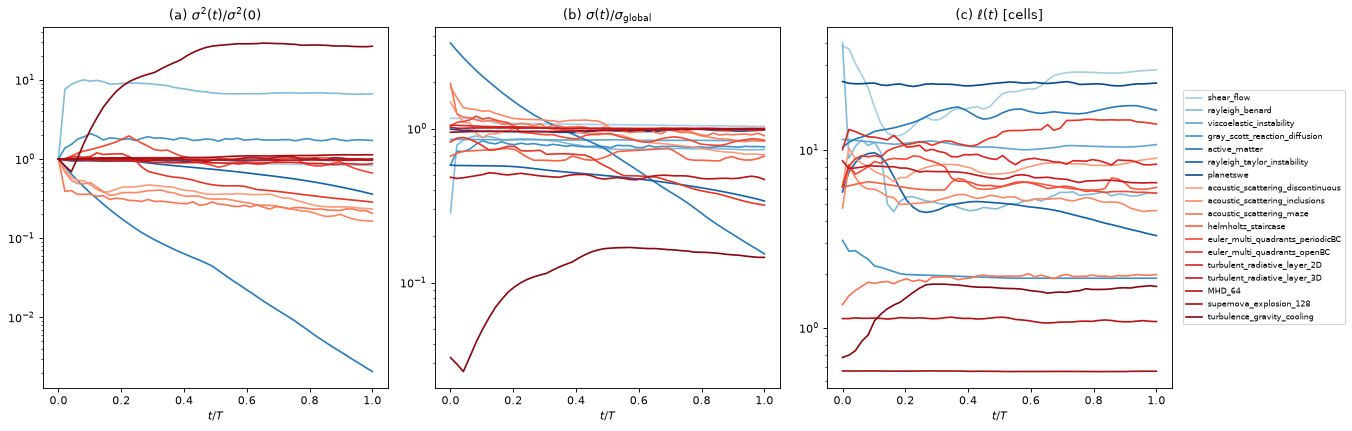

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.5), dpi=80)
for group, cmap in ((DIFFUSIVE, plt.cm.Blues), (NON_DIFFUSIVE, plt.cm.Reds)):
    for i, ds in enumerate(group):
        for ax, m in zip(axs, "abc"):
            ax.plot(T, np.nanmedian(stack(cache[ds], m), 0), color=cmap(0.35 + 0.65 * i / len(group)), label=ds)
for ax, title in zip(axs, ["(a) $\\sigma^2(t)/\\sigma^2(0)$", "(b) $\\sigma(t)/\\sigma_{\\rm global}$", "(c) $\\ell(t)$ [cells]"]):
    ax.set_yscale("log"); ax.set_xlabel("$t/T$"); ax.set_title(title)
axs[2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout(); display(fig); plt.close(fig)

## 2. Per dataset: spread across trajectories

Metric (a), median with the 25–75% band over the 8 trajectories. A narrow band means the behaviour holds across the dataset's parameter range.

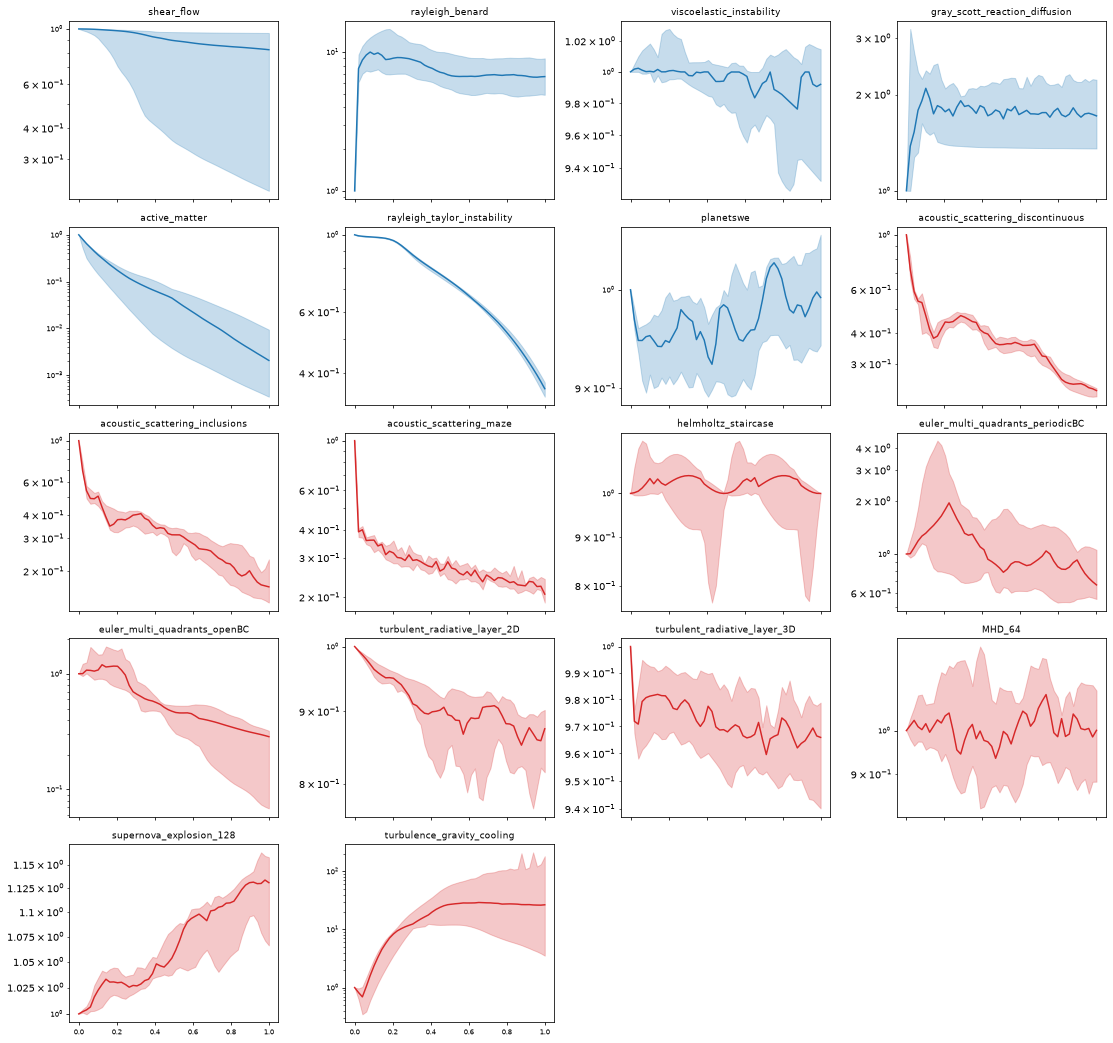

In [13]:
fig, axs = plt.subplots(5, 4, figsize=(16, 15), dpi=70, sharex=True)
for ax, ds in zip(axs.flat, FIELD):
    q = np.nanpercentile(stack(cache[ds], "a"), [25, 50, 75], axis=0)
    c = "tab:blue" if ds in DIFFUSIVE else "tab:red"
    ax.fill_between(T, q[0], q[2], color=c, alpha=0.25); ax.plot(T, q[1], color=c)
    ax.set_yscale("log"); ax.set_title(ds, fontsize=9); ax.tick_params(labelsize=7)
for ax in axs.flat[len(FIELD):]: ax.axis("off")
fig.tight_layout(); display(fig); plt.close(fig)

### 2b. Example trajectories: diffusive

Trajectory 0 of the first and last file of each dataset (titles name the files). Rendered by the GIF cell.

#### `shear_flow`

Kelvin–Helmholtz roll-up of the tracer. At low $Re$ the filaments blur and merge; at high $Re$ fine filaments survive.

![shear_flow](gifs/shear_flow.gif)

#### `rayleigh_benard`

Plumes rising from the hot bottom wall and sinking from the cold top. Diffusion keeps plume edges smooth.

![rayleigh_benard](gifs/rayleigh_benard.gif)

#### `viscoelastic_instability`

$C_{xx}$ (polymer stretch) forms thin sheets that stay sharp: its diffusion $\varepsilon$ is tiny.

![viscoelastic_instability](gifs/viscoelastic_instability.gif)

#### `gray_scott_reaction_diffusion`

Spots or worms form and settle. Their edges keep a fixed finite width set by the two diffusion rates.

![gray_scott_reaction_diffusion](gifs/gray_scott_reaction_diffusion.gif)

#### `active_matter`

Concentration bands form and churn; the field stays smooth throughout.

![active_matter](gifs/active_matter.gif)

#### `rayleigh_taylor_instability`

Heavy fluid sinks into light; the mixing zone grows, with interfaces smoothed by molecular diffusion.

![rayleigh_taylor_instability](gifs/rayleigh_taylor_instability.gif)

#### `planetswe`

Large, smooth weather systems on the globe; hyperviscosity removes only grid-scale noise.

![planetswe](gifs/planetswe.gif)

### 2c. Example trajectories: non-diffusive

#### `acoustic_scattering_discontinuous`

Pressure rings reflect and refract at the density interface; wavefronts stay sharp.

![acoustic_scattering_discontinuous](gifs/acoustic_scattering_discontinuous.gif)

#### `acoustic_scattering_inclusions`

Scattering off many inclusions fills the domain with sharp wavefronts.

![acoustic_scattering_inclusions](gifs/acoustic_scattering_inclusions.gif)

#### `acoustic_scattering_maze`

Waves guided along the maze paths, reflecting sharply at the walls.

![acoustic_scattering_maze](gifs/acoustic_scattering_maze.gif)

#### `helmholtz_staircase`

A time-harmonic field that only cycles in place; nothing smooths or decays.

![helmholtz_staircase](gifs/helmholtz_staircase.gif)

#### `euler_multi_quadrants_periodicBC`

Shocks and contact discontinuities from the quadrant jumps stay sharp as they interact.

![euler_multi_quadrants_periodicBC](gifs/euler_multi_quadrants_periodicBC.gif)

#### `euler_multi_quadrants_openBC`

As periodic, but waves leave through the open boundaries.

![euler_multi_quadrants_openBC](gifs/euler_multi_quadrants_openBC.gif)

#### `turbulent_radiative_layer_2D`

Hot/cold mixing layer; cooling keeps the phase interfaces sharp.

![turbulent_radiative_layer_2D](gifs/turbulent_radiative_layer_2D.gif)

#### `turbulent_radiative_layer_3D`

The same mixing layer in 3D (mid-plane slice).

![turbulent_radiative_layer_3D](gifs/turbulent_radiative_layer_3D.gif)

#### `MHD_64`

Compare the subsonic file (smooth) with the $M_s = 7$ file (sharp, shock-compressed filaments).

![MHD_64](gifs/MHD_64.gif)

#### `supernova_explosion_128`

An expanding blast shell running into a clumpy medium ($\log_{10}$ density).

![supernova_explosion_128](gifs/supernova_explosion_128.gif)

#### `turbulence_gravity_cooling`

Turbulent clouds collapsing into dense filaments ($\log_{10}$ density).

![turbulence_gravity_cooling](gifs/turbulence_gravity_cooling.gif)

## 3. Parameter sweeps

One curve per value of the swept parameter (others fixed), median of 5 trajectories. Expect lower $Re$, $Sc$ or $Ra$ to homogenise faster (falling (a), growing (c)). $t_{\rm cool}$, $\gamma$, $M_s$ and $Z$ change no diffusion term, so any trend there comes from the regime, not from diffusion.

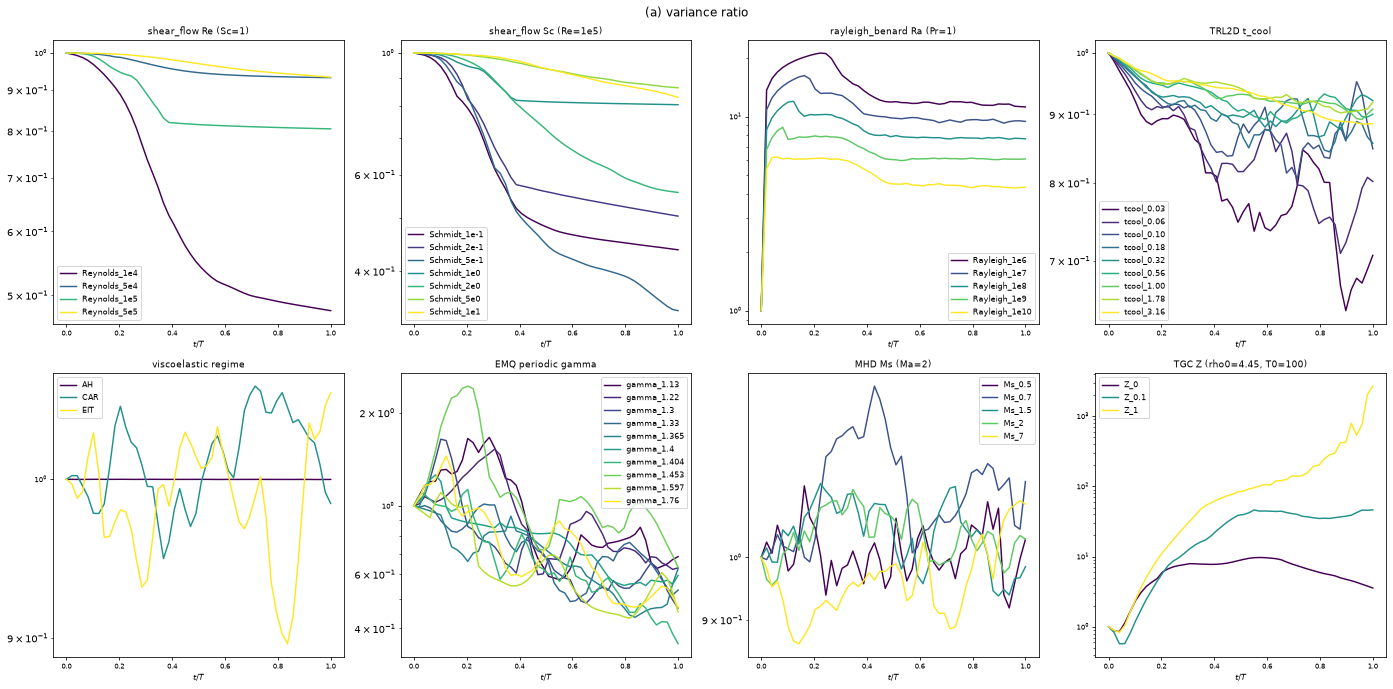

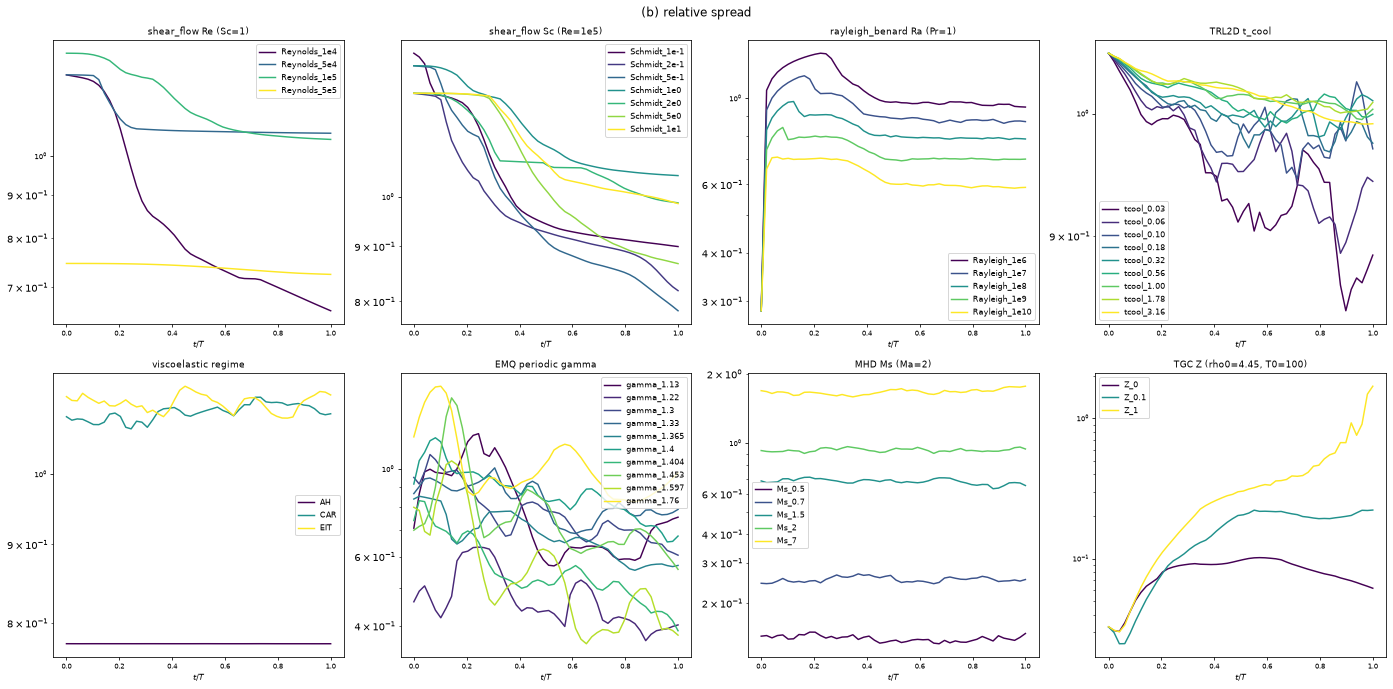

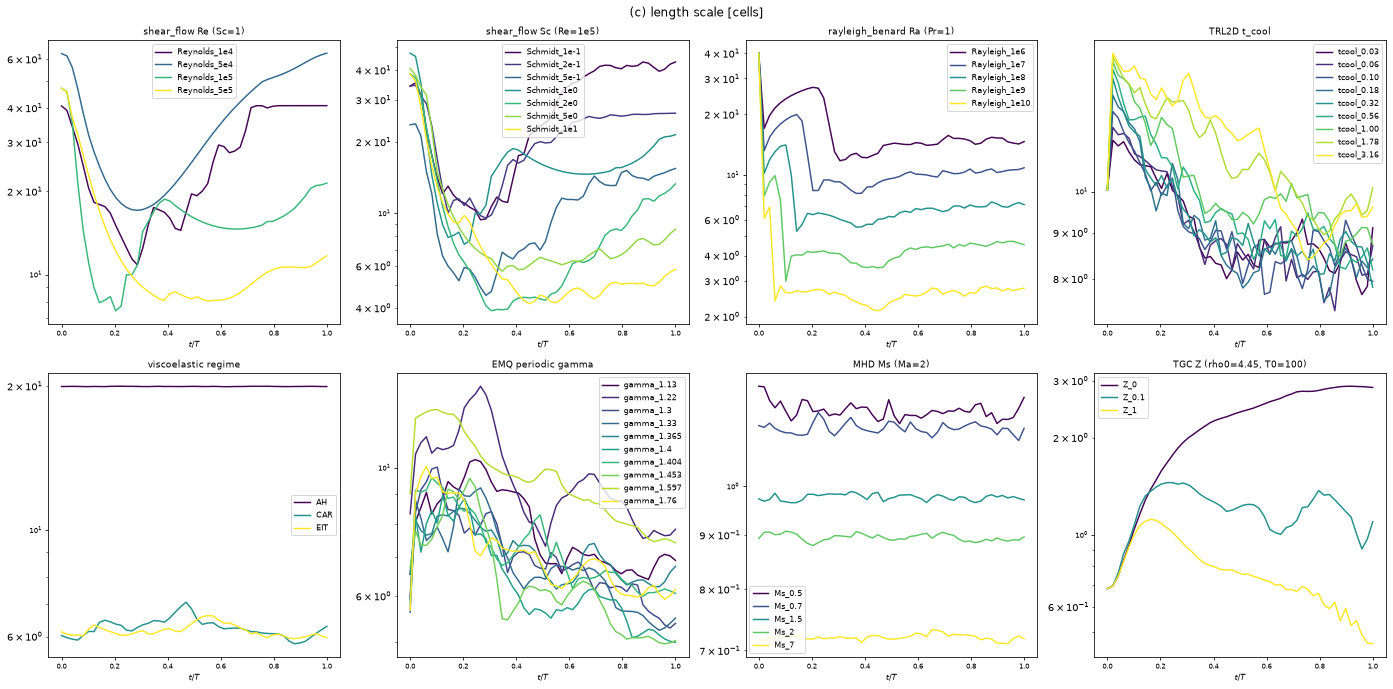

In [14]:
for m, title in (("a", "(a) variance ratio"), ("b", "(b) relative spread"), ("c", "(c) length scale [cells]")):
    fig, axs = plt.subplots(2, 4, figsize=(20, 10), dpi=70)
    for ax, name in zip(axs.flat, SWEEPS):
        keys = sorted((k for k in cache if k.startswith(name + "|")), key=lambda k: value(name, k.split("|")[1])[0])
        for i, k in enumerate(keys):
            ax.plot(T, np.nanmedian(stack(cache[k], m), 0), color=plt.cm.viridis(i / max(len(keys) - 1, 1)),
                    label=value(name, k.split("|")[1])[1])
        ax.set_yscale("log"); ax.set_title(name, fontsize=9); ax.set_xlabel("$t/T$", fontsize=8)
        ax.legend(fontsize=8); ax.tick_params(labelsize=7)
    fig.suptitle(title); fig.tight_layout(); display(fig); plt.close(fig)

### 3b. Sweep examples

Lowest, middle and highest value of each sweep (trajectory 0).

#### shear_flow Re (Sc=1)

![shear_flow Re (Sc=1)](gifs/shear_flow_Re_Sc_1.gif)

#### shear_flow Sc (Re=1e5)

![shear_flow Sc (Re=1e5)](gifs/shear_flow_Sc_Re_1e5.gif)

#### rayleigh_benard Ra (Pr=1)

![rayleigh_benard Ra (Pr=1)](gifs/rayleigh_benard_Ra_Pr_1.gif)

#### TRL2D t_cool

![TRL2D t_cool](gifs/TRL2D_t_cool.gif)

#### viscoelastic regime

![viscoelastic regime](gifs/viscoelastic_regime.gif)

#### EMQ periodic gamma

![EMQ periodic gamma](gifs/EMQ_periodic_gamma.gif)

#### MHD Ms (Ma=2)

![MHD Ms (Ma=2)](gifs/MHD_Ms_Ma_2.gif)

#### TGC Z (rho0=4.45, T0=100)

![TGC Z (rho0=4.45, T0=100)](gifs/TGC_Z_rho0_4_45_T0_100.gif)